# We test GINN against exact solver


Here we look at the physics loss weight or the tolerence $\epsilon$ and show why $\epsilon=10^{-4}$ is the choice for all the analysis.

We also check if GINN is in agreement with an exact numerical geodesic solver, comment about the network's role and also the $\epsilon$ scan.

In [1]:
import sys, copy, warnings, dataclasses
sys.path.insert(0, '..')                      # the package lives one level up
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, torch
import matplotlib.pyplot as plt
%matplotlib inline

from ginn.core import S2Data, keplerian_prefit, LossConfig, train, objective, fit
from ginn.physics import METRICS
from ginn import analysis as an
from ginn import plotting as pl

data = S2Data.from_csv('../data/tab_gillessen_pos.csv', '../data/tab_gillessen_vr.csv')
print(data.summary())

Gillessen+2017: 145 astrometric epochs, 44 RVs, 1992.22-2016.53;  N_data = 334


In [2]:
N_STEPS_GINN   = 5000        
N_STEPS_KEPLER = 2000        
N_STEPS_EXACT  = 1500        
MODEL = dict(hidden=(32, 32),        
             nn_out_scale=1e-3)      
TRAIN = dict(lr_u=0.1,               
             lr_nn=5e-4,             
             lr_floor=0.01,          
             precondition=(0.0,))    

cfg = LossConfig(eps_phys=1e-4,      
                 n_colloc=256,       
                 sigma_w=10.0)       
FRAME = ['x0', 'y0', 'vx0', 'vy0', 'vz0']
LIT = {'inc': 134.18, 'Omega': 226.94, 'omega': 65.51}   
RUN_EPS_SCAN = True
EPS_LIST = [3e-2, 1e-2, 3e-3, 1e-3, 3e-4, 1e-4, 3e-5, 1e-5]
N_STEPS_SCAN = 3000
metric = METRICS['schwarzschild']

## Pretraining

In [3]:
init = keplerian_prefit(data)

Keplerian pre-fit (astrometry only): chi2 = 297.4
  M=4.1419e+06, a=1023.6, e=0.87929, inc=134.79, Omega=224.95, omega=63.536, t0=2002.3, D=8.3, P=16.0909 yr


## Full training

schwarzschild/ginn:   0%|          | 0/5000 [00:00<?, ?it/s]

M = 4.2110e6 Msun | a = 1030.09 AU | e = 0.88725 | i = 134.087 | Om = 227.396 | om = 65.884 | t_p = 2002.3285 | D = 8.0785 kpc | vz0 = 10.25 km/s
   frame: x0 = +0.720 mas | y0 = -2.489 mas | vx0 = +0.1209 mas/yr | vy0 = +0.0118 mas/yr


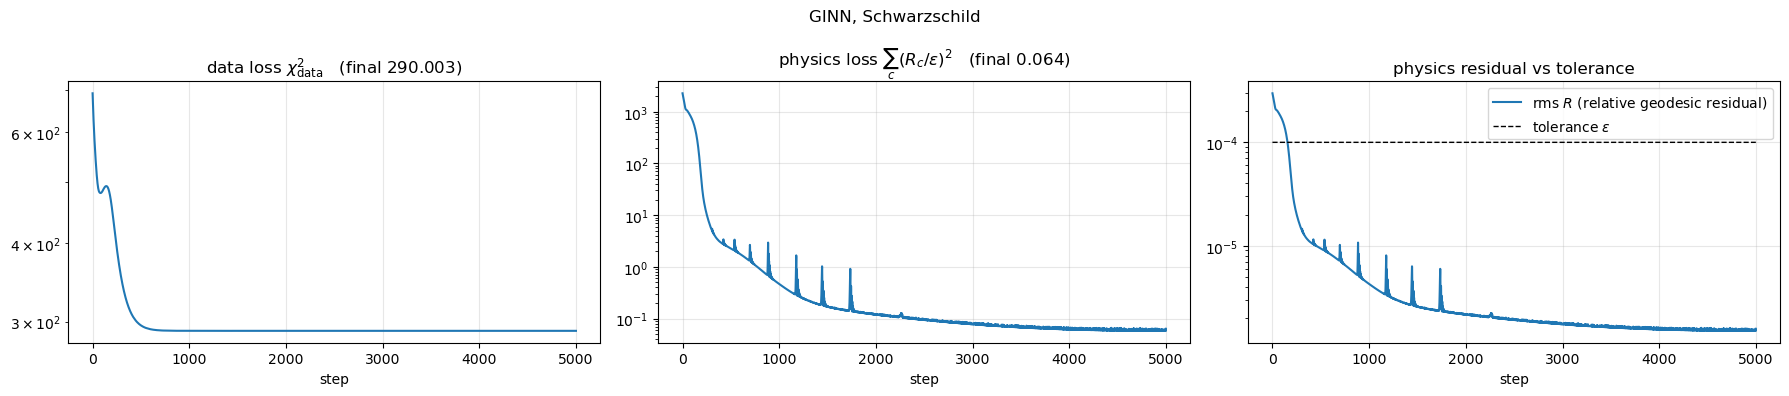

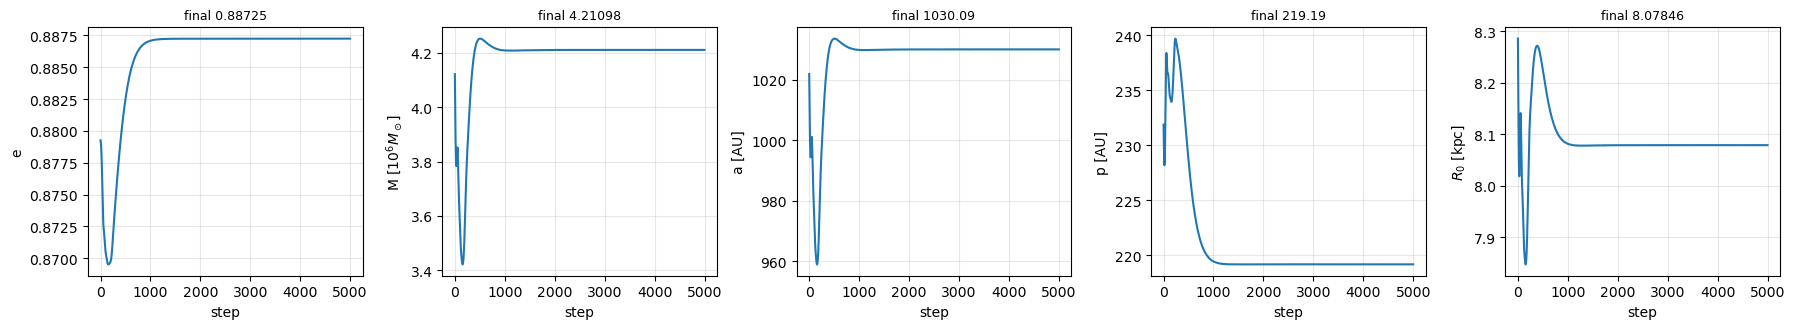

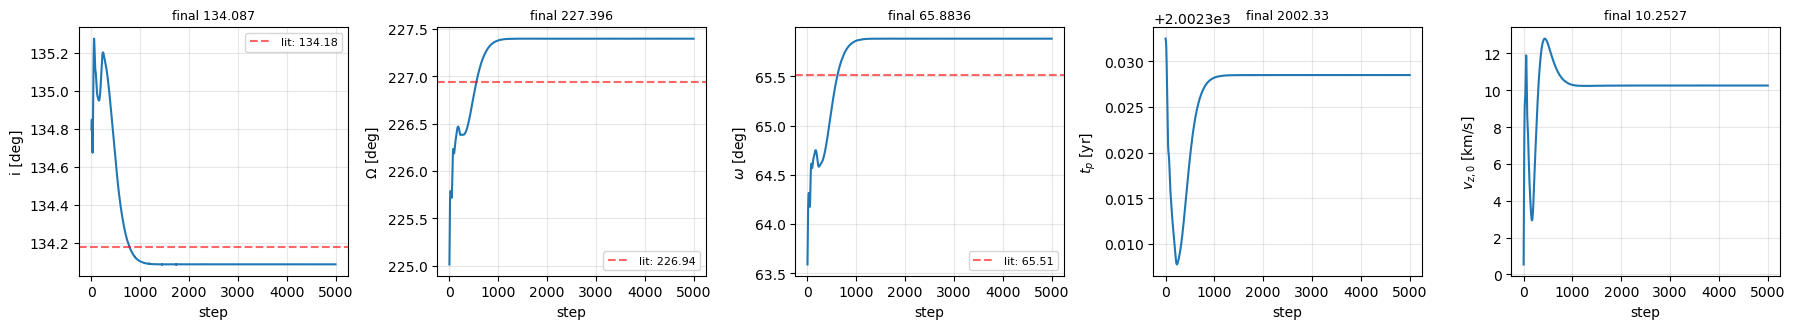

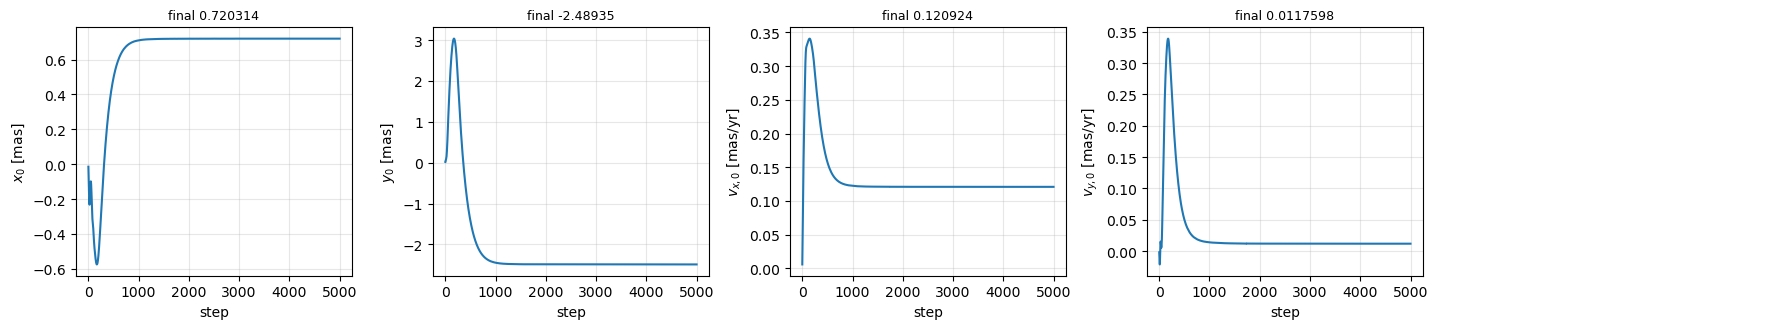

In [4]:
ginn, hist = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN, **MODEL, **TRAIN)
print(ginn.summary())
pl.plot_loss_history(hist, 'GINN, Schwarzschild'); plt.show()
pl.plot_param_history(hist, lit=LIT); plt.show()

## Reference fits 
* Kepler: the network is switched of and $\chi(t)$ is purely Keplerian.
* Exact numerical solver: $\chi(t)$ comes from Newton inversion of the exact quadrature $t(\chi)$. This is the numerically obtained ground truth we want the network to reproduce. It is used only for verification.

schwarzschild/kepler:   0%|          | 0/2000 [00:00<?, ?it/s]

schwarzschild/exact:   0%|          | 0/1500 [00:00<?, ?it/s]

GINN    M = 4.2110e6 Msun | a = 1030.09 AU | e = 0.88725 | i = 134.087 | Om = 227.396 | om = 65.884 | t_p = 2002.3285 | D = 8.0785 kpc | vz0 = 10.25 km/s
   frame: x0 = +0.720 mas | y0 = -2.489 mas | vx0 = +0.1209 mas/yr | vy0 = +0.0118 mas/yr
Kepler  M = 4.2140e6 Msun | a = 1030.33 AU | e = 0.88722 | i = 134.093 | Om = 227.390 | om = 65.875 | t_p = 2002.3285 | D = 8.0808 kpc | vz0 = 10.29 km/s
   frame: x0 = +0.719 mas | y0 = -2.499 mas | vx0 = +0.1212 mas/yr | vy0 = +0.0119 mas/yr
exact   M = 4.2113e6 Msun | a = 1030.12 AU | e = 0.88725 | i = 134.087 | Om = 227.396 | om = 65.884 | t_p = 2002.3285 | D = 8.0786 kpc | vz0 = 10.26 km/s
   frame: x0 = +0.721 mas | y0 = -2.491 mas | vx0 = +0.1209 mas/yr | vy0 = +0.0116 mas/yr


C:\Users\phys6\Downloads\GINN_final\GINN\notebooks\..\ginn\plotting.py:67: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  t0 = min(data.t_span[0], float(model.physical()['t0'])) - 1


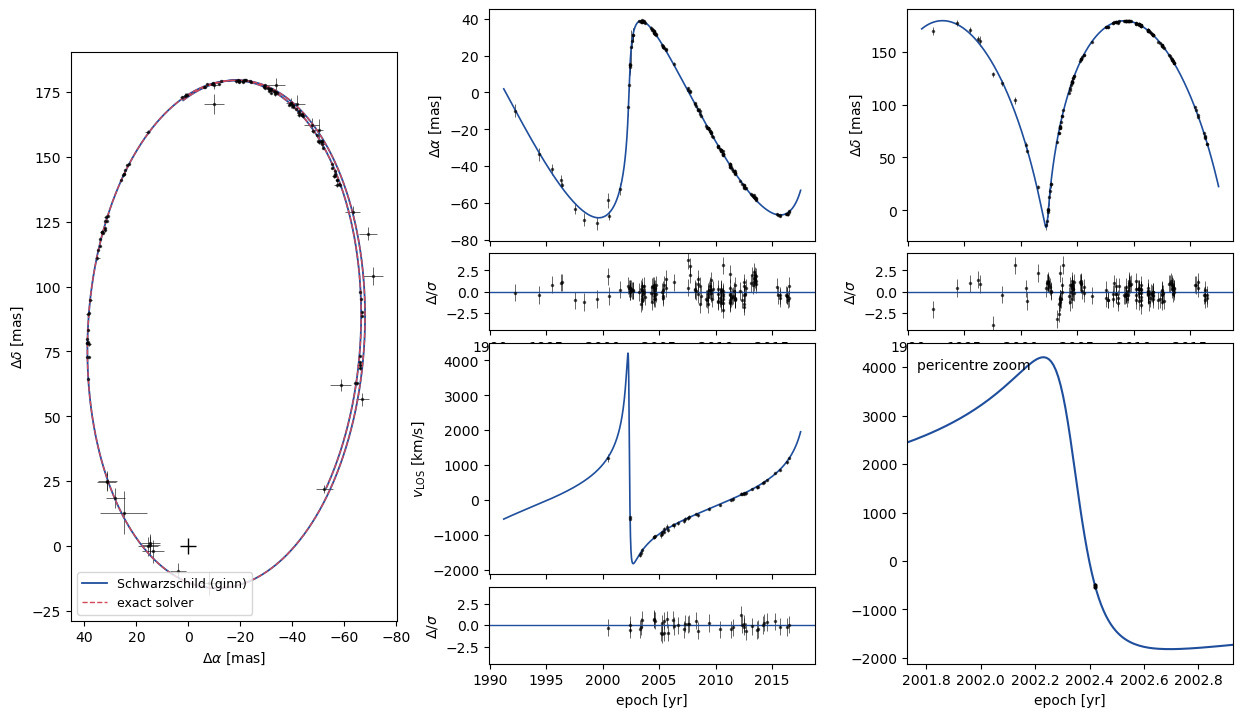

In [5]:
kepler, _ = fit(metric, data, init, timing='kepler', cfg=cfg, n_steps=N_STEPS_KEPLER, **TRAIN)
exact,  _ = fit(metric, data, init, timing='exact',  cfg=cfg, n_steps=N_STEPS_EXACT, **TRAIN)
for lab, m in [('GINN', ginn), ('Kepler', kepler), ('exact', exact)]:
    print(f'{lab:7s}', m.summary())
pl.plot_fit(ginn, data, others={'exact solver': exact}); plt.show()

## Network's role can we quantified as follows

* $\chi^2_{\rm Kepler}-\chi^2_{\rm exact}$ is the most the we can improve the fit. We want the network to deliver that much gain. More would mean overfitting the noise.
* $\delta\chi_{\rm NN}$ should overlay $\delta\chi_{\rm exact}$.
* The Fisher information on each parameter that flows through the network's response to that parameter. The response is computed from the implicit-function derivative $d\theta^*/du$ of the physics-optimal weights. A negative share means the true timing response partly cancels the other channels. Ignoring the network would then overstate the constraint.
* Parameter shift: The GINN MAP minus the exact-solver MAP, in Laplace σ.

chi2 (N_data = 334)                     RA      Dec      RV     total
  GINN                                         140.76   137.68   11.57   290.003
  without network                              140.78   137.79   11.53   290.096
  geodesic timing numerical                    140.76   137.68   11.57   290.002
  Kepler fit                                   140.78   137.73   11.56   290.071
  Numerical fit                                140.75   137.68   11.57   290.001
we compare chi-squared improvement due to GINN and exact numerical correction - should be more or less equal
Kepler - exact numerical: chi2(Kepler) - chi2(exact) = 0.070
Kepler - GINN:                     chi2(Kepler) - chi2(GINN)  = 0.069


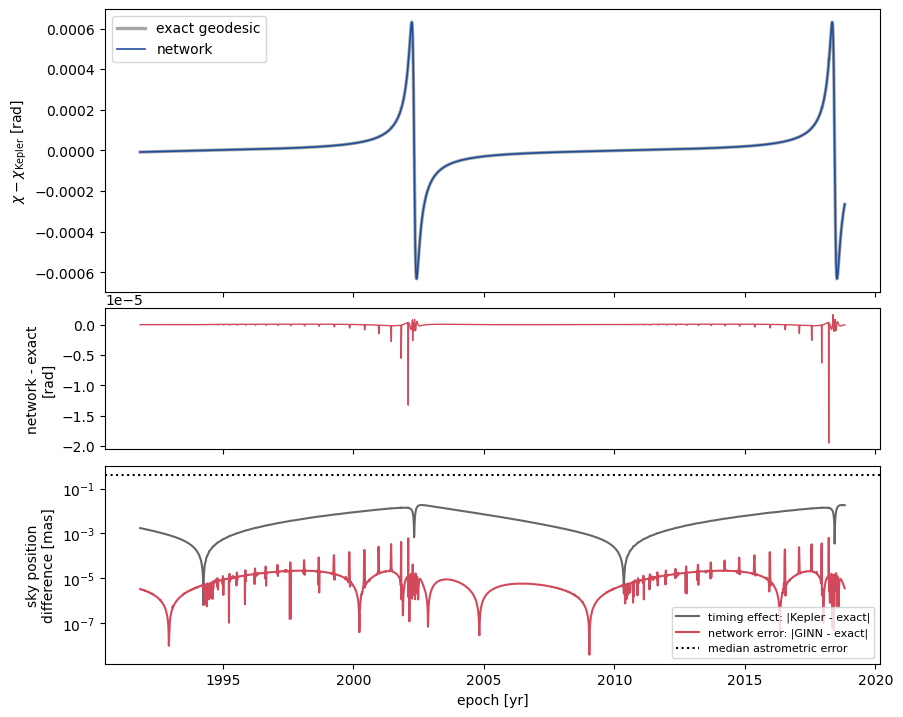

In [6]:
lap_ginn  = an.laplace(ginn, data, cfg)                 # network marginalised
lap_exact = an.laplace(exact, data, cfg)
rep = an.nn_role_report(ginn, data, cfg, kepler=kepler, exact=exact, lap=lap_ginn)
pl.plot_timing(rep['timing_curves'], data); plt.show()

#This table checks two things- whether the network reproduces the exact correction (exact w.r.t to the numerical), 
#and how much the correction matters for these data.

# Everything except the chi(t) is computed exactly (I mean E, L, \varphi(t) etc)

# Network GINN: the Kepler solution chi_K (with n_r) plus the network correction.
# Without network: χ_K alone
# Exact numerical: the numerical solution from the inversion of t(\chi).

# We use the same best fit parameters (from GINN best fit) and only change chi(t)
# only in the last two rows we do full refitting - Kepler vs numerical
# The network reproduces the exact solution to within 0.002 (more or less but in this order)
#

## Posterior


param           GINN (marginalised)             GINN (NN frozen)                 exact solver
M             4.21404 ± 0.231              4.21261 ± 0.191              4.21439 ± 0.231      
D             8.08287 ± 0.229              8.08086 ± 0.204              8.08305 ± 0.229      
a             127.489 ± 1.39               127.498 ± 1.35                127.49 ± 1.39       
e            0.887199 ± 0.00279           0.887207 ± 0.00271           0.887204 ± 0.00279    
inc           134.098 ± 0.551              134.094 ± 0.529              134.098 ± 0.551      
Omega         227.387 ± 0.734              227.395 ± 0.706              227.387 ± 0.734      
omega         65.8687 ± 0.735              65.8785 ± 0.697              65.8688 ± 0.735      
t0            2002.33 ± 0.00635            2002.33 ± 0.0061             2002.33 ± 0.00635    
vz0           10.2786 ± 7.83               10.3168 ± 7.58               10.2828 ± 7.82       


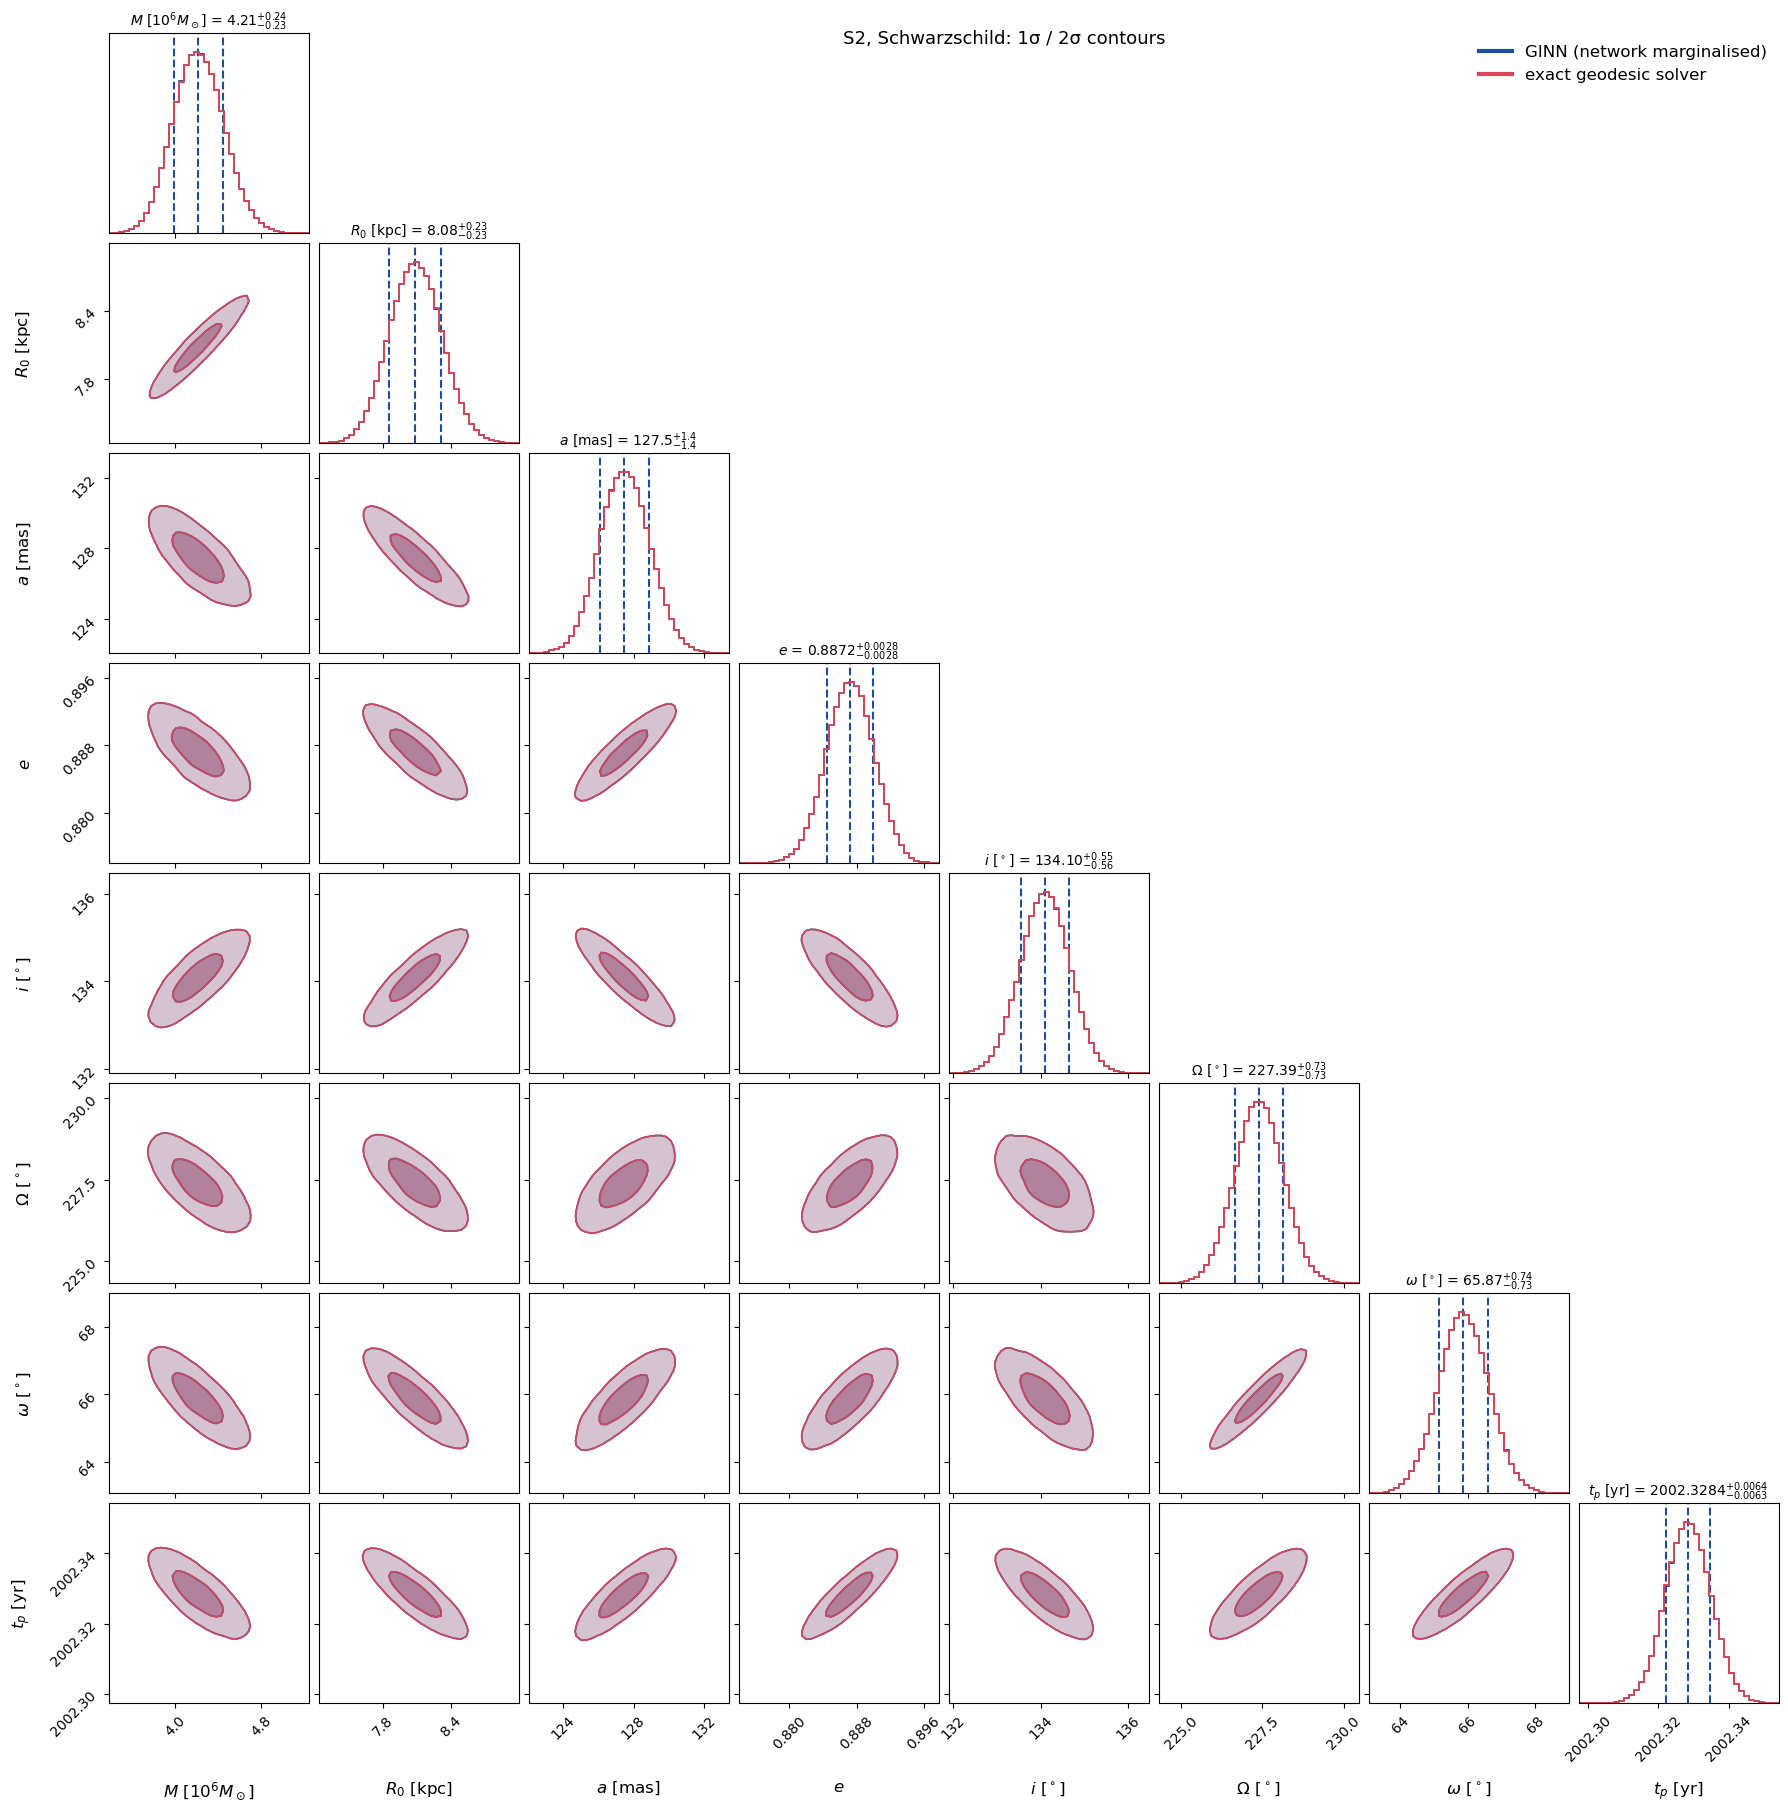

In [7]:
lap_frozen = an.laplace(ginn, data, cfg, marginalize_nn=False)
S_ginn, S_frz, S_ex = (an.sample_laplace(ginn, lap_ginn), an.sample_laplace(ginn, lap_frozen),
                       an.sample_laplace(exact, lap_exact))
keys = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0']
print(f"{'param':6s} {'GINN (marginalised)':>28s} {'GINN (NN frozen)':>28s} {'exact solver':>28s}")
for k in keys + ['vz0']:
    row = [an.summarize(S)[k] for S in (S_ginn, S_frz, S_ex)]
    print(f"{k:6s} " + " ".join(f"{m:14.6g} ± {0.5*(a+b):<11.3g}" for m, a, b in row))
fig = pl.corner_plot([S_ginn, S_ex], an.labels_for(ginn), keys,
                     names=['GINN (network marginalised)', 'exact geodesic solver'],
                     title='S2, Schwarzschild: 1σ / 2σ contours')
plt.show()

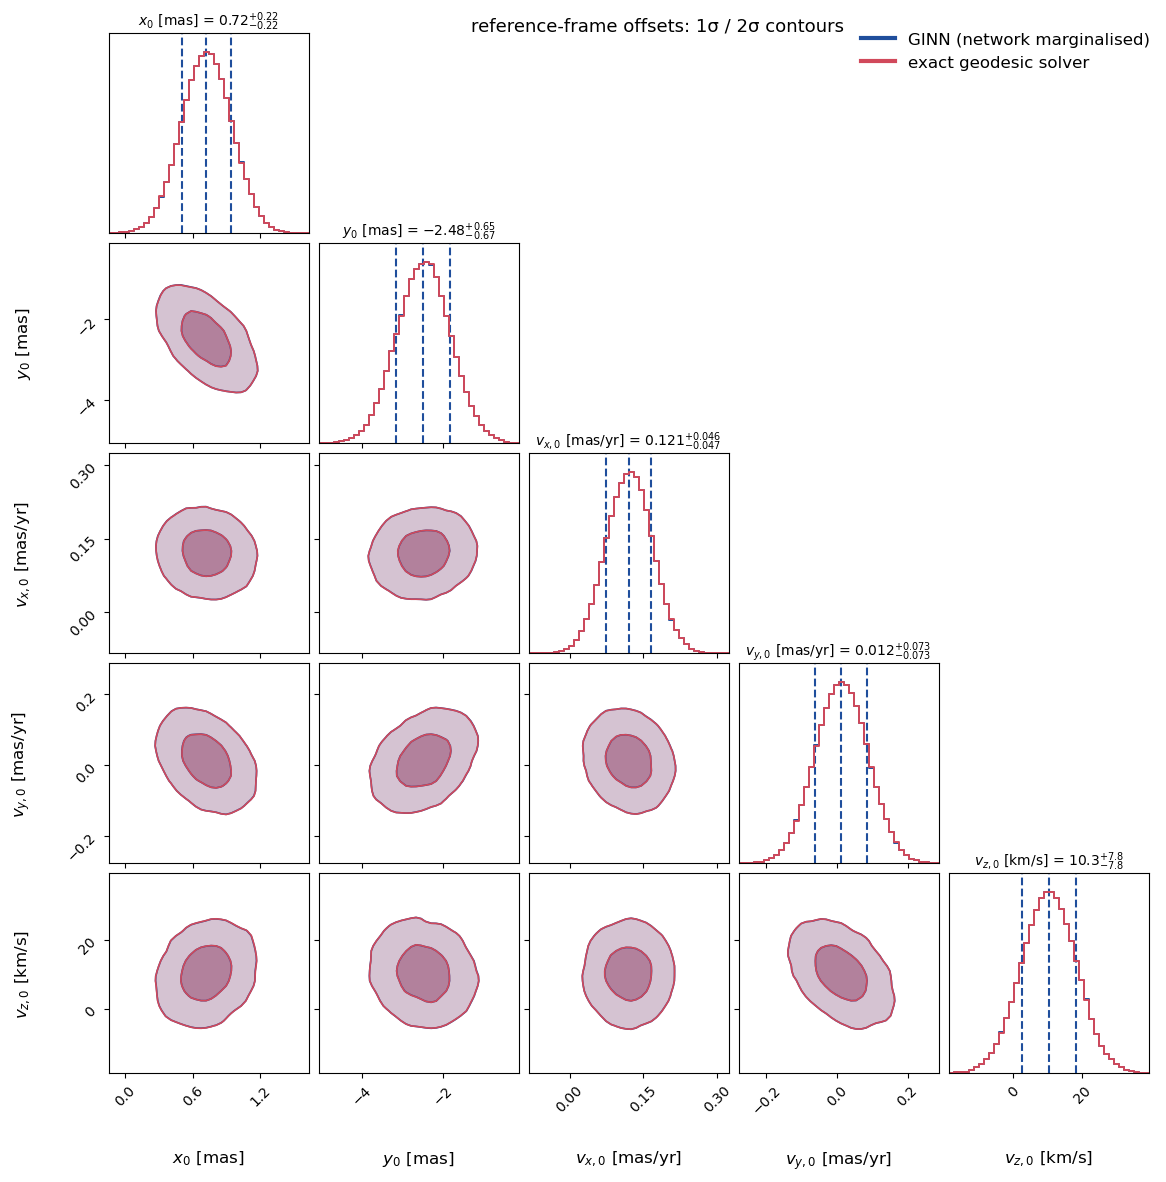

x0   = +0.719 +- 0.219
y0   = -2.479 +- 0.662
vx0  = +0.121 +- 0.046
vy0  = +0.012 +- 0.073
vz0  = +10.279 +- 7.827


In [8]:
# reference-frame parameters (fitted jointly with the orbit)
fig = pl.corner_plot([S_ginn, S_ex], an.labels_for(ginn), FRAME,
                     names=['GINN (network marginalised)', 'exact geodesic solver'],
                     title='reference-frame offsets: 1σ / 2σ contours')
plt.show()
for k in FRAME:
    m_, lo_, hi_ = an.summarize(S_ginn)[k]; print(f"{k:4s} = {m_:+.3f} +- {0.5*(lo_+hi_):.3f}")

## Physics weight (tolerance $\epsilon$)

The joint fit is repeated for a range of $\epsilon$ and compared with the exact numerical solver. 

* $\epsilon$ too large ($\gtrsim3\times10^{-3}$): Overfitting. The network is not well constrained by the geodesic and fits noise. $\chi^2$ drops below the exact geodesic's benchmark. $M$ and $R_0$ are biased, and $\delta\chi_{\rm NN}$ is several times the true GR correction.

* Plateau for ($10^{-4}\lesssim\epsilon\lesssim10^{-3}$): Converged. $\chi^2$, $M$, $R_0$ and the timing all equal the exact solver and no longer depend on $\epsilon$. So in this range $\epsilon$ is reproduces the numerical solver tolerance. And this is how we have selected the physics loss. 

  
* When $\epsilon$ too small ($\lesssim3\times10^{-5}$): too stiff. It is forced to get closer to the geodesic. But the loss surface becomes very steep and its hard for Adam to converge, so $\chi^2$ ends above the exact value.


In [9]:
scan = []
if RUN_EPS_SCAN:
    for eps in EPS_LIST:
        c_eps = dataclasses.replace(cfg, eps_phys=eps)
        m_eps, h_eps = fit(metric, data, init, timing='ginn', cfg=c_eps, n_steps=N_STEPS_SCAN,
                           progress=False, **MODEL, **TRAIN)
        tc = an.timing_comparison(m_eps)
        P = m_eps.physical()
        scan.append(dict(eps=eps, chi2=an.chi2_parts(m_eps, data)['total'], M=P['M'].item()/1e6,
                         D=P['D'].item(), mism=np.sqrt(np.mean((tc['dchi_nn'] - tc['dchi_exact'])**2)),
                         nn=np.sqrt(np.mean(tc['dchi_nn']**2)), ex=np.sqrt(np.mean(tc['dchi_exact']**2)),
                         model=m_eps, tc=tc))
        r = scan[-1]
        print(f"eps = {eps:.0e}:  chi2 = {r['chi2']:8.3f}   M = {r['M']:.4f}   R0 = {r['D']:.4f}   "
              f"rms dchi_NN = {r['nn']:.2e} (exact {r['ex']:.2e}),  mismatch = {r['mism']:.1e}")

eps = 3e-02:  chi2 =  267.148   M = 4.3009   R0 = 8.1910   rms dchi_NN = 9.49e-04 (exact 1.20e-04),  mismatch = 9.8e-04
eps = 1e-02:  chi2 =  289.096   M = 4.2188   R0 = 8.0910   rms dchi_NN = 1.54e-04 (exact 1.19e-04),  mismatch = 1.7e-04
eps = 3e-03:  chi2 =  289.634   M = 4.2132   R0 = 8.0818   rms dchi_NN = 1.19e-04 (exact 1.19e-04),  mismatch = 1.7e-05
eps = 1e-03:  chi2 =  289.963   M = 4.2113   R0 = 8.0788   rms dchi_NN = 1.19e-04 (exact 1.19e-04),  mismatch = 2.1e-06
eps = 3e-04:  chi2 =  290.001   M = 4.2111   R0 = 8.0785   rms dchi_NN = 1.19e-04 (exact 1.19e-04),  mismatch = 5.2e-07
eps = 1e-04:  chi2 =  290.004   M = 4.2107   R0 = 8.0784   rms dchi_NN = 1.19e-04 (exact 1.19e-04),  mismatch = 5.2e-07
eps = 3e-05:  chi2 =  311.396   M = 4.1684   R0 = 8.2430   rms dchi_NN = 1.15e-04 (exact 1.15e-04),  mismatch = 8.9e-07
eps = 1e-05:  chi2 =  531.443   M = 3.2024   R0 = 7.6672   rms dchi_NN = 9.34e-05 (exact 9.35e-05),  mismatch = 3.8e-07


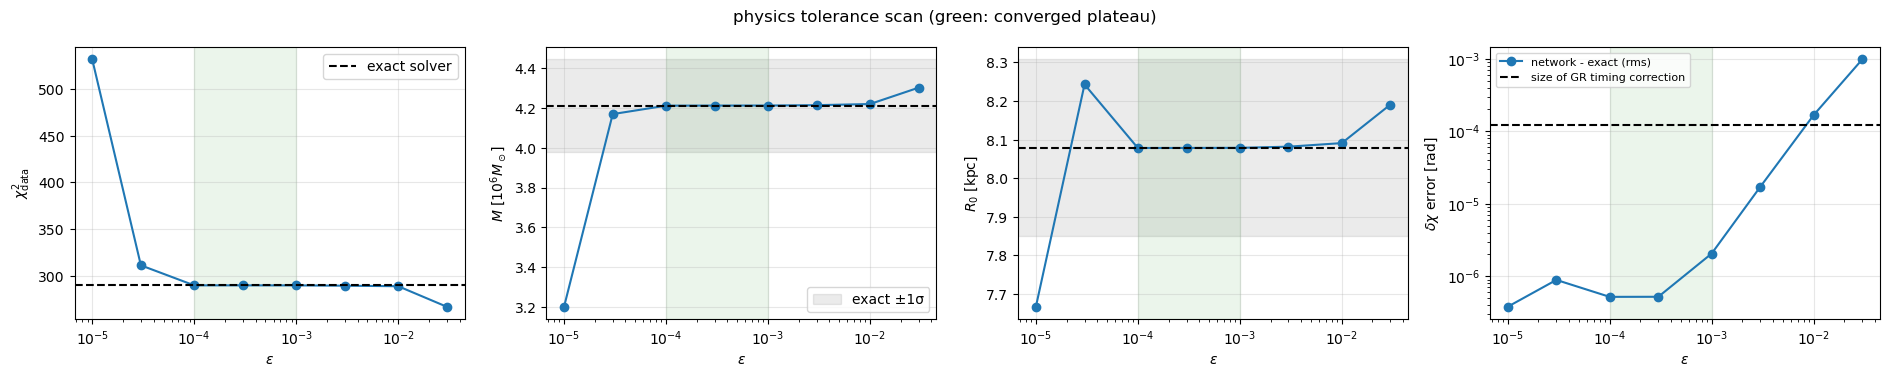

loosest eps: network timing vs exact


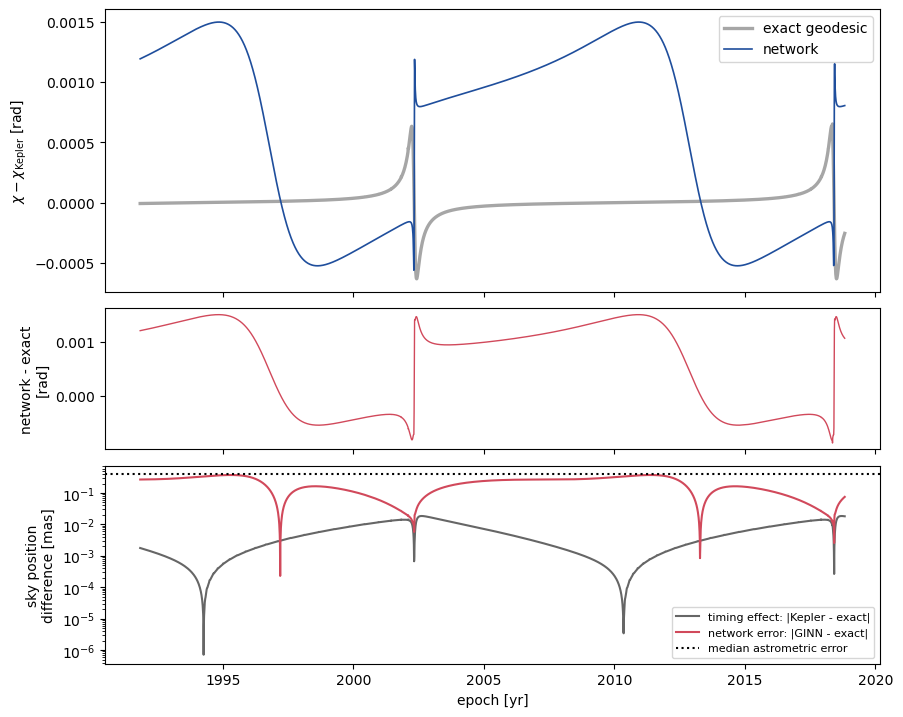

In [10]:
if scan:
    e_ = np.array([r['eps'] for r in scan])
    ref = dict(chi2=an.chi2_parts(exact, data, 'exact')['total'], M=exact.physical()['M'].item()/1e6,
               D=exact.physical()['D'].item())
    sM = an.summarize(S_ex)['M']; sD = an.summarize(S_ex)['D']
    fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
    ax[0].semilogx(e_, [r['chi2'] for r in scan], 'o-'); ax[0].axhline(ref['chi2'], color='k', ls='--', label='exact solver')
    ax[0].set_ylabel(r'$\chi^2_{\rm data}$')
    ax[1].semilogx(e_, [r['M'] for r in scan], 'o-'); ax[1].axhline(ref['M'], color='k', ls='--')
    ax[1].axhspan(ref['M'] - 0.5*(sM[1]+sM[2]), ref['M'] + 0.5*(sM[1]+sM[2]), color='k', alpha=0.08, label='exact ±1σ')
    ax[1].set_ylabel(r'$M\ [10^6M_\odot]$')
    ax[2].semilogx(e_, [r['D'] for r in scan], 'o-'); ax[2].axhline(ref['D'], color='k', ls='--')
    ax[2].axhspan(ref['D'] - 0.5*(sD[1]+sD[2]), ref['D'] + 0.5*(sD[1]+sD[2]), color='k', alpha=0.08)
    ax[2].set_ylabel(r'$R_0$ [kpc]')
    ax[3].loglog(e_, [r['mism'] for r in scan], 'o-', label='network - exact (rms)')
    ax[3].axhline(scan[0]['ex'], color='k', ls='--', label='size of GR timing correction')
    ax[3].set_ylabel(r'$\delta\chi$ error [rad]')
    for a in ax:
        a.set_xlabel(r'$\epsilon$'); a.axvspan(1e-4, 1e-3, color='g', alpha=0.08); a.grid(alpha=0.3)
    ax[0].legend(); ax[1].legend(); ax[3].legend(fontsize=8)
    fig.suptitle(r'physics tolerance scan (green: converged plateau)'); plt.tight_layout(); plt.show()
    print('loosest eps: network timing vs exact')
    pl.plot_timing(scan[0]['tc'], data); plt.show()

In [11]:
c = {k: rep[k]['total'] for k in ('chi2_ginn', 'chi2_kepler_refit', 'chi2_exact_refit')}
dof = data.n_points - int(ginn.free.sum())
print(f"GINN chi2 = {c['chi2_ginn']:.3f} (chi2/dof = {c['chi2_ginn']/dof:.3f}), exact = {c['chi2_exact_refit']:.3f}, "
      f"Kepler timing = {c['chi2_kepler_refit']:.3f}")
print(f"network reproduces the exact GR timing correction to "
      f"{100*rep['timing']['rms_mismatch']/rep['timing']['rms_dchi_exact']:.1f}% (rms)")
sM = an.summarize(S_ginn)['M']; sD = an.summarize(S_ginn)['D']
print(f"M = {sM[0]:.3f} (+{sM[2]:.3f} / -{sM[1]:.3f}) x 1e6 Msun,  R0 = {sD[0]:.3f} (+{sD[2]:.3f} / -{sD[1]:.3f}) kpc")

GINN chi2 = 290.003 (chi2/dof = 0.903), exact = 290.001, Kepler timing = 290.071
network reproduces the exact GR timing correction to 0.4% (rms)
M = 4.214 (+0.236 / -0.226) x 1e6 Msun,  R0 = 8.083 (+0.229 / -0.230) kpc


## Higher-order expansion and the exact geodesic solver
For every spacetime, the posterior of the second-order expansion (sampled with MCMC) is compared with the Gauss–Newton + Laplace posterior of its notebook and with the exact geodesic solver, which uses neither the network nor any expansion. The exact-solver posterior is obtained by reweighting the MCMC samples with $w\propto e^{-(\Delta\chi^2_{\rm exact}-\Delta\chi^2_{\rm higher\ order})/2}$; the fraction of effective samples after reweighting measures the agreement directly (1 = identical). The model notebooks must be run first.

In [12]:
from ginn import higher_order as ho
import os
KEYS = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0']
ORDER = ['schwarzschild', 'hairy_horndeski', 'yukawa', 'reissner_nordstrom', 'bardeen', 'jnw']
val = {}
for name in ORDER:
    f = f'results/{name}.pt'
    if not os.path.exists(f) or 'post' not in torch.load(f, weights_only=False):
        print(f'{name}: run its notebook first'); continue
    r = torch.load(f, weights_only=False)
    m, post = r['model'], r['post']
    hair = [hp.name for hp in an.free_hair(m, post)]
    keys = KEYS + hair
    P = ho.Expansion(m, data, post, r['cfg']).expand()
    chain = ho.sample(P, 'dali', n=600_000)
    exr = ho.reweight_exact(P, chain, n=6000)
    st = {'laplace': ho.stats(ho.sample(P, 'laplace'), keys), 'dali': ho.stats(chain, keys), 'exact': ho.stats(exr, keys)}
    pw = ho.pointwise(P)
    print(f'\n========== {m.metric.label}')
    print('|Delta chi2 - exact| at 20 points 1.5 sigma away (median, max):  ' +
          '   '.join(f"{k} {np.median(v):.2f}, {v.max():.2f}" for k, v in pw.items()))
    print(f"exact-solver reweighting: {exr['n_eff']:.0f} of {exr['n']} samples effective"
          + ('' if exr['n_eff'] > 0.5 * exr['n'] else '   <- the expansion or the network is not reliable here'))
    ho.print_compare(st, keys, names=('dali', 'exact'), hair=hair)
    val[name] = dict(label=m.metric.label, st=st, hair=hair, ess=exr['n_eff'] / exr['n'],
                     labels=an.labels_for(m), profiles=[ho.profile(P, h, exact=True) for h in hair])


========== Schwarzschild
|Delta chi2 - exact| at 20 points 1.5 sigma away (median, max):  laplace 1.59, 120.31   newton 1.55, 118.62   dali 0.04, 10.89
exact-solver reweighting: 5993 of 6000 samples effective
             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew |       exact: shift, sd ratio, skew
M               4.21675 +- 0.231     |      +0.06       0.960       +0.18 |      +0.06       0.969       +0.24 |
D                8.0813 +- 0.228     |      +0.06       0.944       +0.04 |      +0.06       0.948       +0.09 |
a               127.519 +- 1.39      |      -0.04       0.943       +0.21 |      -0.05       0.943       +0.20 |
e              0.887217 +- 0.0028    |      -0.04       0.942       +0.08 |      -0.04       0.945       +0.06 |
inc             134.087 +- 0.554     |      +0.06       0.943       -0.04 |      +0.05       0.942       -0.04 |
Omega           227.397 +- 0.73      |      -0.08       0.959       +0.07 |      -0.08       0.971       +0.03 |
om

The chain is shorter than 50 times the integrated autocorrelation time for 2 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 194;
tau: [203.7533252  191.28945836 174.96620268 180.64416219 188.97355009
 150.25888978 185.03278848 185.99005898 173.45627546 181.59121047
 208.10140138 162.36449177 182.19785974 169.71470778]



========== Horndeski
|Delta chi2 - exact| at 20 points 1.5 sigma away (median, max):  laplace 2.07, 445.58   newton 2.10, 443.40   dali 0.07, 41.10
exact-solver reweighting: 5989 of 6000 samples effective
             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew |       exact: shift, sd ratio, skew
M               4.34114 +- 0.251     |      -0.07       0.965       +0.15 |      -0.09       0.965       +0.12 |
D               8.11022 +- 0.226     |      -0.07       0.961       +0.01 |      -0.09       0.964       +0.02 |
a               127.434 +- 1.36      |      +0.06       0.961       +0.25 |      +0.08       0.970       +0.21 |
e              0.885483 +- 0.00306   |      +0.07       0.952       +0.08 |      +0.09       0.963       +0.08 |
inc             134.112 +- 0.545     |      -0.06       0.956       -0.10 |      -0.08       0.964       -0.06 |
Omega           227.245 +- 0.729     |      +0.03       0.971       -0.01 |      +0.04       0.975       -0.02 |
omega 

The chain is shorter than 50 times the integrated autocorrelation time for 2 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 194;
tau: [233.79706    182.6363363  174.81768389 202.02951907 169.1769862
 159.72093742 167.20809393 188.23596446 168.2718509  169.37614781
 186.07189978 156.97071929 184.80600811 182.9452783 ]



========== Yukawa
|Delta chi2 - exact| at 20 points 1.5 sigma away (median, max):  laplace 3.54, 408.96   newton 3.43, 405.91   dali 0.07, 38.23
exact-solver reweighting: 5989 of 6000 samples effective
             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew |       exact: shift, sd ratio, skew
M               4.29909 +- 0.242     |      +0.08       1.000       +0.24 |      +0.09       0.992       +0.21 |
D               8.12213 +- 0.228     |      +0.05       0.982       +0.09 |      +0.07       0.974       +0.07 |
a               127.315 +- 1.36      |      -0.00       0.967       +0.16 |      -0.01       0.964       +0.17 |
e              0.885379 +- 0.00303   |      -0.00       0.981       -0.02 |      +0.00       0.975       -0.00 |
inc             134.168 +- 0.545     |      +0.04       0.976       -0.04 |      +0.05       0.977       -0.06 |
Omega           227.194 +- 0.738     |      -0.06       0.976       +0.00 |      -0.07       0.967       +0.01 |
omega    

The chain is shorter than 50 times the integrated autocorrelation time for 14 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 194;
tau: [330.57330225 299.99226804 291.06549109 300.0133652  275.0706888
 453.47700226 258.86427579 301.38600655 272.07047887 475.55775818
 459.59145746 471.16472921 452.97804434 608.96253501]



========== RN
|Delta chi2 - exact| at 20 points 1.5 sigma away (median, max):  laplace 229.95, 5029.10   newton 229.24, 5035.67   dali 11.21, 360.07
exact-solver reweighting: 5740 of 6000 samples effective
             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew |       exact: shift, sd ratio, skew
M                4.2134 +- 0.23      |      +0.06       0.971       +0.14 |      +0.07       0.960       +0.12 |
D               8.07881 +- 0.228     |      +0.05       0.957       -0.01 |      +0.06       0.951       -0.02 |
a               127.523 +- 1.39      |      -0.03       0.944       +0.21 |      -0.04       0.949       +0.20 |
e              0.887219 +- 0.0028    |      +0.08       0.962       +0.09 |      +0.07       0.956       +0.07 |
inc             134.084 +- 0.554     |      +0.05       0.958       -0.10 |      +0.06       0.955       -0.07 |
Omega           227.402 +- 0.732     |      -0.04       0.969       +0.01 |      -0.06       0.963       +0.04 |
omega

The chain is shorter than 50 times the integrated autocorrelation time for 14 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 194;
tau: [320.93371322 269.26881015 287.07860897 311.07511352 248.96428994
 430.57247053 287.55864748 310.74351799 273.35874068 526.77870597
 461.11341238 494.44363421 467.17440883 564.59568609]



========== Bardeen
|Delta chi2 - exact| at 20 points 1.5 sigma away (median, max):  laplace 365.75, 7015.13   newton 363.67, 7016.72   dali 28.73, 953.11
exact-solver reweighting: 4971 of 6000 samples effective
             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew |       exact: shift, sd ratio, skew
M               4.21321 +- 0.23      |      +0.10       0.971       +0.21 |      +0.08       0.963       +0.31 |
D               8.07874 +- 0.228     |      +0.10       0.953       +0.08 |      +0.08       0.949       +0.16 |
a               127.522 +- 1.39      |      -0.08       0.945       +0.11 |      -0.07       0.944       +0.11 |
e              0.887215 +- 0.0028    |      +0.06       0.952       +0.05 |      +0.06       0.965       +0.06 |
inc             134.084 +- 0.554     |      +0.10       0.958       +0.04 |      +0.08       0.954       +0.07 |
Omega           227.402 +- 0.732     |      -0.07       0.950       +0.00 |      -0.07       0.961       -0.00 |


metric           hair       sigma GN   sigma HO  sigma exact  ESS exact                   95% GN                 95% HO              95% exact
Horndeski        q            0.0038   0.003887     0.003875       1.00      [-0.00258, +0.0123]      [-0.003, +0.0123]    [-0.00314, +0.0121]
Yukawa           delta       0.01402    0.01443       0.0143       1.00      [-0.00704, +0.0479]    [-0.00635, +0.0496]    [-0.00579, +0.0494]
RN               Q             2.159      1.845        1.815       0.96           [-4.11, +4.35]          [-3.35, +3.8]         [-3.27, +3.71]
Bardeen          g_b           57.23      44.06         42.7       0.83             [-112, +113]         [-75.9, +89.3]         [-75.9, +81.7]
JNW              q_jnw         109.5      86.04        84.21       0.88             [-217, +213]           [-164, +168]           [-159, +163]


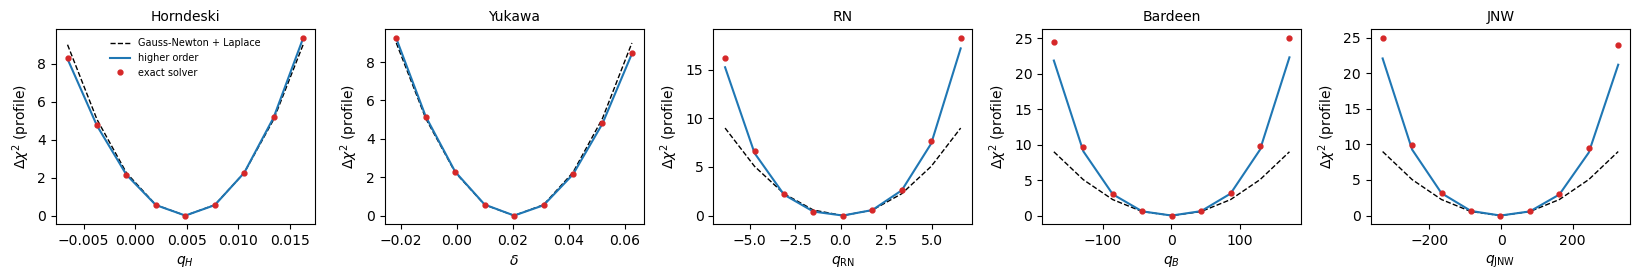

In [13]:
print(f"{'metric':16s} {'hair':8s} {'sigma GN':>10s} {'sigma HO':>10s} {'sigma exact':>12s} {'ESS exact':>10s}"
      f"   {'95% GN':>22s} {'95% HO':>22s} {'95% exact':>22s}")
for name, v in val.items():
    for h in v['hair']:
        s = {k: v['st'][k][h] for k in ('laplace', 'dali', 'exact')}
        iv = lambda d: f"[{d['lo95']:+.3g}, {d['hi95']:+.3g}]"
        print(f"{v['label']:16s} {h:8s} {s['laplace']['sd']:10.4g} {s['dali']['sd']:10.4g} {s['exact']['sd']:12.4g} "
              f"{v['ess']:10.2f}   {iv(s['laplace']):>22s} {iv(s['dali']):>22s} {iv(s['exact']):>22s}")
prs = [(v, pr) for v in val.values() for pr in v['profiles']]
if prs:
    fig, axs = plt.subplots(1, len(prs), figsize=(3.3 * len(prs), 2.9), squeeze=False)
    for a_, (v, pr) in zip(axs[0], prs):
        ho.plot_profile(a_, pr, label=v['labels'][pr['name']])
        a_.set_title(v['label'], fontsize=10)
    axs[0][0].legend(fontsize=7, frameon=False)
    plt.tight_layout(); plt.savefig('results/hair_profiles.pdf'); plt.show()

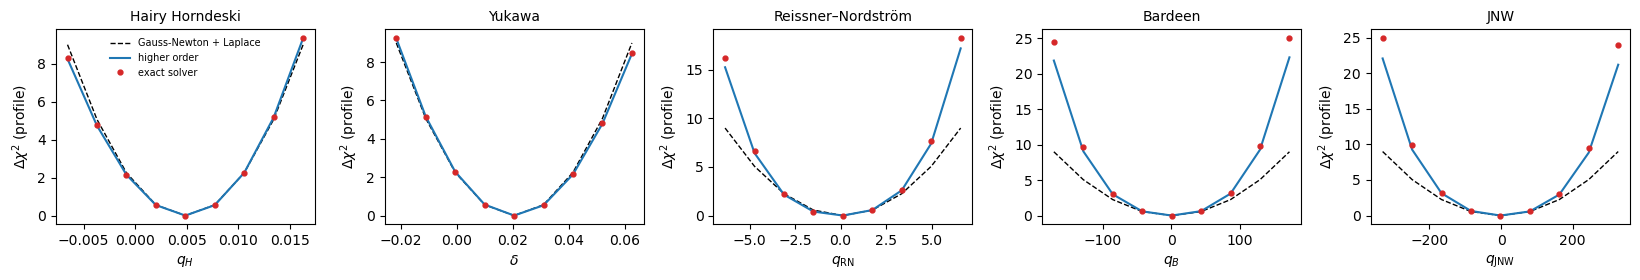

In [18]:
prs = [(v, pr) for v in val.values() for pr in v['profiles']]
if prs:
    fig, axs = plt.subplots(1, len(prs), figsize=(3.3 * len(prs), 2.9), squeeze=False)
    
    # Map the short labels to the full descriptive names
    label_map = {
        'Horndeski': r'Hairy Horndeski',
        'RN': r'Reissner–Nordström'
    }
    
    for a_, (v, pr) in zip(axs[0], prs):
        # 1. Change the legend label
        orig_label = v['labels'][pr['name']]
        plot_label = label_map.get(orig_label, orig_label)
        ho.plot_profile(a_, pr, label=plot_label)
        
        # 2. Change the title label
        orig_title = v['label']
        plot_title = label_map.get(orig_title, orig_title)
        a_.set_title(plot_title, fontsize=10)
        
    axs[0][0].legend(fontsize=7, frameon=False)
    plt.tight_layout(); plt.savefig('results/hair_profiles.pdf'); plt.show()